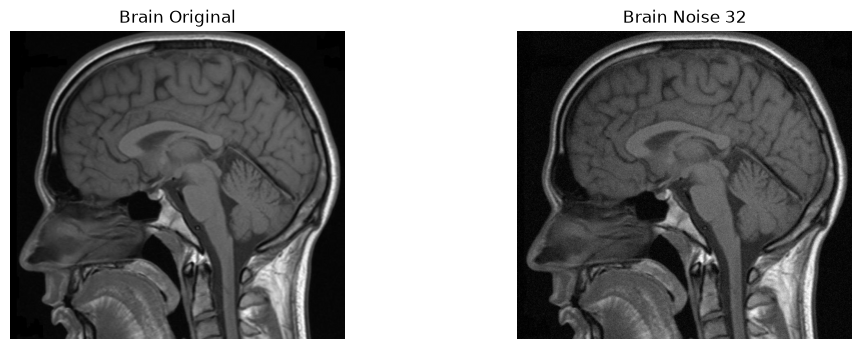

In [14]:
from io import BytesIO
from urllib.request import urlopen
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

brain = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/brain.jpg")

with urlopen(brain) as response:
    brain = Image.open(BytesIO(response.read()))

brain_array = np.array(brain, dtype=np.float32)

num_images = 32
mean = 0
sigma = 50 # Era 25 mas não achei visível o suficiente então dupliquei

noisy_images = []

for i in range(num_images):
    noise = np.random.normal(mean, sigma, brain_array.shape)
    noisy_array = brain_array + noise
    noisy_array_clipped = np.clip(noisy_array, 0, 255).astype(np.uint8)
    noisy_images.append(noisy_array_clipped)

noisy_stack = np.array(noisy_images)

#______________________________________________________________________________________________________________________________________________________________________________
# Deixei a seção abaixo comentada para não exibir todas as imagens com ruído. 
# Senti a necessidade de verificar se o ruído estava sendo aplicado corretamente.
# Testei com a constante de ruído sigma = 25 e não achei visível o suficiente, então dupliquei para sigma = 50.
#______________________________________________________________________________________________________________________________________________________________________________
#display_images = [Image.fromarray(noisy_stack[i]) for i in range(num_images)]

#fig, axes = plt.subplots(8, 4, figsize=(12, 24), constrained_layout=True)

#for i, ax in enumerate(axes.flat):
    #ax.imshow(display_images[i], cmap="gray")
    #ax.axis('off')
#______________________________________________________________________________________________________________________________________________________________________________

median_array = np.median(noisy_stack, axis=0).astype(np.uint8)

final_median_img = Image.fromarray(median_array)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].imshow(brain, cmap="gray")
axes[0].set_title("Brain Original")

axes[1].imshow(final_median_img, cmap="gray")
axes[1].set_title("Brain Noise 32")

for ax in axes:
    ax.axis('off')
plt.show()

plt.show()